# 04 - Concept agreement (RQ1, RQ3)

Per-member contributions (`03_ensembles.ipynb`) are summed per ontology concept (`02_ontology.ipynb`) into concept
vectors `c_m(x, k)` (absolute contributions, normalised to sum to 1), at both ontology levels:
`top` = 5 level-1 concepts, `leaf` = 10 level-2 concepts. The `protected` view splits the same mass into
`ProtectedAttribute` (race, sex, relationship) vs `Other`.

- **RQ1.** Do members of one ensemble rely on the same concepts for a sample? Does this change with the level?
- **RQ3.** Do tree members and LR members show different agreement patterns?

Everything is computed on the official test split (16,281 samples), 100 members per ensemble.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

from project_acl import concepts, ensemble, ontology
from project_acl.preprocess import encode, read, split

sns.set_theme(style="white", context="notebook")
FIG = Path("../docs/figures")
FIG.mkdir(exist_ok=True)

df = read()
X, y, source = encode(df)
X_tr, X_te, y_tr, y_te = split(X, y, df)
X_te, y_te = X_te.to_numpy(float), y_te.to_numpy()
models = ensemble.build(X_tr, y_tr)
proba = {name: ensemble.member_proba(m, X_te) for name, m in models.items()}

# concept vectors v[ensemble, level]: (members, samples, concepts); phi is dropped once aggregated (677 MB each)
LEVELS = {"top": 1, "leaf": 2, "protected": concepts.PROTECTED_VIEW}
labels = {lvl: concepts.column_concepts(X.columns, source, l) for lvl, l in LEVELS.items()}
v, names = {}, {}
for name, m in models.items():
    phi = ensemble.member_contributions(m, X_te)
    for lvl in LEVELS:
        v[name, lvl], names[lvl] = concepts.concept_vectors(phi, labels[lvl])
    del phi
{lvl: names[lvl] for lvl in LEVELS}

[16:27:55] INFO     fitted RF: 100 members                                                           ]8;id=12524952;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=12524953;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

[16:28:00] INFO     fitted LR: 100 members                                                           ]8;id=12524958;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=12524959;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

{'top': ['Demographics', 'Education', 'Employment', 'Family', 'Finance'],
 'leaf': ['Age',
  'Capital',
  'EducationLevel',
  'HouseholdRole',
  'MaritalStatus',
  'Occupation',
  'Origin',
  'Sector',
  'Sex',
  'WorkTime'],
 'protected': ['Other', 'ProtectedAttribute']}

## 1. Agreement per sample

Per sample, over the 100 members:
- `top_agreement`: share of members whose top concept is the most common one (1 = all members agree);
- `entropy`: entropy of the members' top-concept distribution, divided by `log(#concepts)` so both levels are on 0..1
  (0 = all members agree);
- `kendall`: mean pairwise Kendall tau-b between the members' concept vectors (1 = same ranking of all concepts).

`shuffled` is a chance reference: each member's concept vector is permuted at random for each sample, which keeps
the values but destroys which concept they belong to.

In [2]:
METRICS = ["top_agreement", "entropy", "kendall"]
rng = np.random.default_rng(ensemble.SEED)
parts = []
for name in models:
    for lvl in ["top", "leaf"]:
        # shuffled: permute each member's concept values across concepts, separately per sample
        for kind, vec in [("observed", v[name, lvl]), ("shuffled", rng.permuted(v[name, lvl], axis=2))]:
            parts.append(concepts.agreement(vec).assign(ensemble=name, level=lvl, kind=kind))
agree = pd.concat(parts, ignore_index=True)
agree.groupby(["kind", "level", "ensemble"])[METRICS].mean().unstack("kind").round(3)

top_agreement           entropy           kendall         
kind                observed shuffled observed shuffled observed shuffled
level ensemble                                                           
leaf  LR               0.509    0.151    0.499    0.980    0.373     -0.0
      RF               0.534    0.151    0.452    0.980    0.352     -0.0
top   LR               0.786    0.253    0.375    0.987    0.481      0.0
      RF               0.834    0.253    0.300    0.987    0.410      0.0

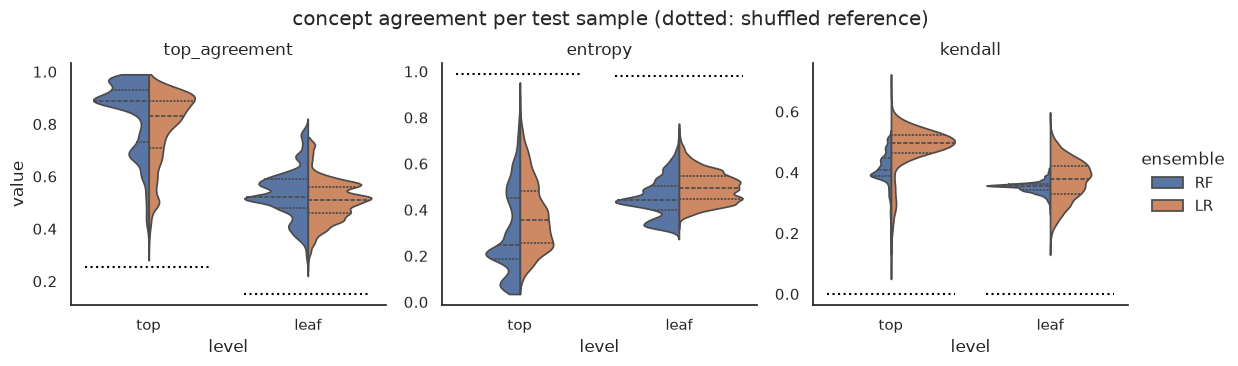

In [3]:
obs = agree[agree.kind == "observed"].melt(id_vars=["ensemble", "level"], value_vars=METRICS, var_name="metric")
g = sns.catplot(obs, x="level", y="value", hue="ensemble", col="metric", kind="violin", split=True, inner="quartile",
                cut=0, sharey=False, height=3.5, aspect=1.1, order=["top", "leaf"])
g.set_titles("{col_name}")
for ax, metric in zip(g.axes.flat, METRICS):
    ref = agree[agree.kind == "shuffled"].groupby("level")[metric].mean()
    for x, lvl in enumerate(["top", "leaf"]):
        ax.hlines(ref[lvl], x - 0.4, x + 0.4, colors="black", linestyles=":")
g.figure.suptitle("concept agreement per test sample (dotted: shuffled reference)", y=1.04);
plt.gcf().savefig(FIG / "agreement_by_level.png", dpi=200, bbox_inches="tight")

RQ3 on the same samples: paired comparison of RF vs LR agreement (positive = RF members agree more).

In [4]:
obs_w = agree[agree.kind == "observed"]
paired = []
for lvl in ["top", "leaf"]:
    rf, lr = (obs_w[(obs_w.ensemble == e) & (obs_w.level == lvl)][METRICS].reset_index(drop=True) for e in models)
    d = rf - lr
    paired.append(pd.DataFrame({"level": lvl, "metric": METRICS, "mean RF - LR": d.mean().values,
                                "share RF > LR": (d > 0).mean().values, "share RF < LR": (d < 0).mean().values}))
pd.concat(paired).round(3)

,level,metric,mean RF - LR,share RF > LR,share RF < LR
0,top,top_agreement,0.048,0.651,0.309
1,top,entropy,-0.075,0.313,0.685
2,top,kendall,-0.071,0.167,0.833
0,leaf,top_agreement,0.026,0.536,0.395
1,leaf,entropy,-0.047,0.321,0.678
2,leaf,kendall,-0.022,0.359,0.641


## 2. Which concepts do members rely on?

Share of (member, sample) pairs in which each concept is the top concept, and the member x concept heatmap of
mean concept shares (rows = members, grouped by their dominant concept).

mean share        top share       
ensemble                     LR     RF        LR     RF
level concept                                          
leaf  Age                 0.032  0.076     0.003  0.055
      Capital             0.067  0.107     0.035  0.043
      EducationLevel      0.155  0.186     0.133  0.115
      HouseholdRole       0.221  0.202     0.296  0.290
      MaritalStatus       0.233  0.307     0.430  0.451
      Occupation          0.131  0.044     0.065  0.027
      Origin              0.040  0.001     0.011  0.000
      Sector              0.037  0.002     0.008  0.001
      Sex                 0.062  0.013     0.013  0.004
      WorkTime            0.022  0.061     0.005  0.014
top   Demographics        0.134  0.090     0.040  0.054
      Education           0.155  0.186     0.075  0.102
      Employment          0.190  0.108     0.089  0.040
      Family              0.454  0.507     0.771  0.761
      Finance             0.067  0.107     0.026  0.043

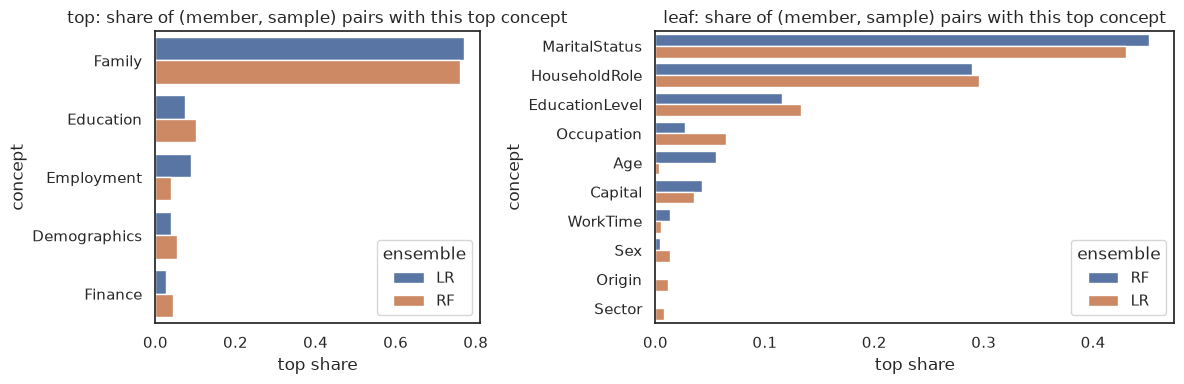

In [5]:
rows = []
for name in models:
    for lvl in ["top", "leaf"]:
        top = v[name, lvl].argmax(axis=2)
        mean = v[name, lvl].mean(axis=(0, 1))
        rows += [(name, lvl, c, (top == k).mean(), mean[k]) for k, c in enumerate(names[lvl])]
top_share = pd.DataFrame(rows, columns=["ensemble", "level", "concept", "top share", "mean share"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, lvl in zip(axes, ["top", "leaf"]):
    d = top_share[top_share.level == lvl].sort_values("top share", ascending=False)
    sns.barplot(d, y="concept", x="top share", hue="ensemble", ax=ax)
    ax.set_title(f"{lvl}: share of (member, sample) pairs with this top concept")
plt.tight_layout()
plt.gcf().savefig(FIG / "top_concepts.png", dpi=200, bbox_inches="tight")
top_share.pivot_table(index=["level", "concept"], columns="ensemble", values=["top share", "mean share"]).round(3)

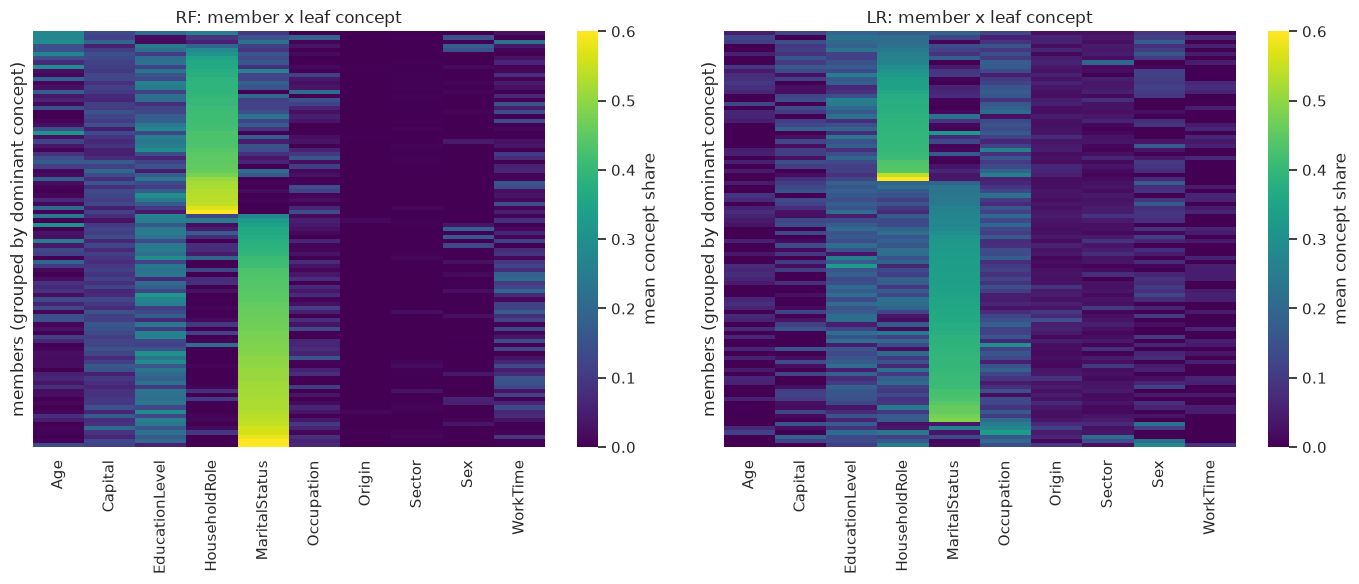

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, models):
    mc = pd.DataFrame(v[name, "leaf"].mean(axis=1), columns=names["leaf"])
    order = mc.assign(_top=mc.idxmax(axis=1), _max=mc.max(axis=1)).sort_values(["_top", "_max"]).index
    sns.heatmap(mc.loc[order], ax=ax, cmap="viridis", vmin=0, vmax=0.6, yticklabels=False,
                cbar_kws={"label": "mean concept share"})
    ax.set(title=f"{name}: member x leaf concept", ylabel="members (grouped by dominant concept)")
plt.tight_layout()
plt.gcf().savefig(FIG / "member_concept_heatmap.png", dpi=200, bbox_inches="tight")

Spread between members: standard deviation over members of each member's mean concept share (leaf level).
High values mean members specialise on different concepts.

In [7]:
pd.DataFrame({name: v[name, "leaf"].mean(axis=1).std(axis=0) for name in models}, index=names["leaf"]).round(3)

,RF,LR
Age,0.085,0.036
Capital,0.035,0.060
EducationLevel,0.070,0.055
HouseholdRole,0.204,0.124
MaritalStatus,0.195,0.155
Occupation,0.047,0.058
Origin,0.002,0.022
Sector,0.004,0.033
Sex,0.038,0.058
WorkTime,0.058,0.027


## 3. ProtectedAttribute view

Share of each member's absolute contribution that goes to `race`, `sex` and `relationship` (relationship is a proxy
for sex). The features stay in the models: the aim is to
measure how much the members rely on them.

,member mean,member min,member max,"share of (member, sample) > 0.5"
RF,0.216,0.000,0.649,0.171
LR,0.301,0.026,0.681,0.137


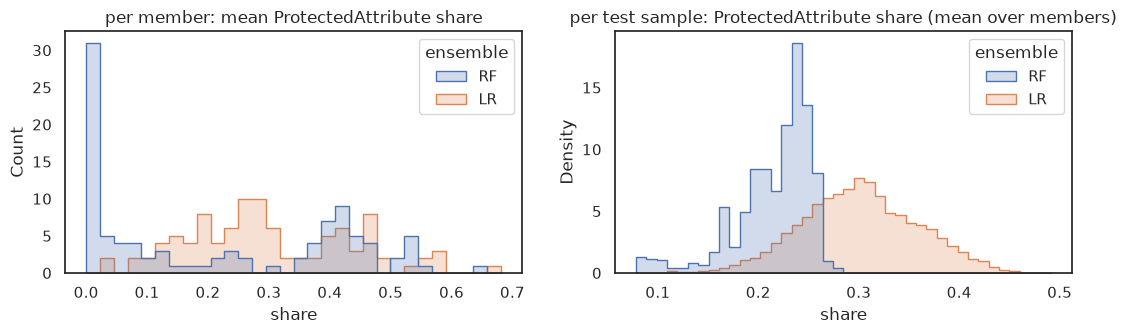

In [8]:
k = names["protected"].index(ontology.PROTECTED)
prot = {name: v[name, "protected"][..., k] for name in models}
member_prot = pd.DataFrame({name: p.mean(axis=1) for name, p in prot.items()})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(member_prot.melt(var_name="ensemble", value_name="share"), x="share", hue="ensemble", bins=30,
             element="step", ax=axes[0])
axes[0].set_title("per member: mean ProtectedAttribute share")
sns.histplot(pd.DataFrame({n: p.mean(axis=0) for n, p in prot.items()}).melt(var_name="ensemble", value_name="share"),
             x="share", hue="ensemble", bins=40, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("per test sample: ProtectedAttribute share (mean over members)")
plt.tight_layout()
plt.gcf().savefig(FIG / "protected_share.png", dpi=200, bbox_inches="tight")
pd.DataFrame({"member mean": member_prot.mean(), "member min": member_prot.min(), "member max": member_prot.max(),
              "share of (member, sample) > 0.5": pd.Series({n: (p > 0.5).mean() for n, p in prot.items()})}).round(3)

## 4. Faithfulness check

For each member and leaf concept: accuracy drop when all columns of the concept are permuted together over the
test split (one shared row permutation keeps one-hot groups valid). If the attribution is faithful, concepts with a
high mean share should show a high drop. Per member: Spearman correlation between its 10 mean concept shares and
its 10 drops.

per-member Spearman(attribution, accuracy drop):
            RF       LR
count  100.000  100.000
mean     0.768    0.891
std      0.137    0.071
min      0.293    0.632
25%      0.695    0.855
50%      0.784    0.898
75%      0.867    0.939
max      0.975    1.000


mean share        mean accuracy drop       
ensemble               LR     RF                 LR     RF
concept                                                   
Age                 0.032  0.076              0.002  0.003
Capital             0.067  0.107              0.019  0.038
EducationLevel      0.155  0.186              0.037  0.041
HouseholdRole       0.221  0.202              0.024  0.022
MaritalStatus       0.233  0.307              0.044  0.038
Occupation          0.130  0.044              0.015  0.011
Origin              0.040  0.001              0.001  0.000
Sector              0.037  0.002              0.003  0.000
Sex                 0.062  0.013              0.006  0.001
WorkTime            0.022  0.061              0.003  0.003

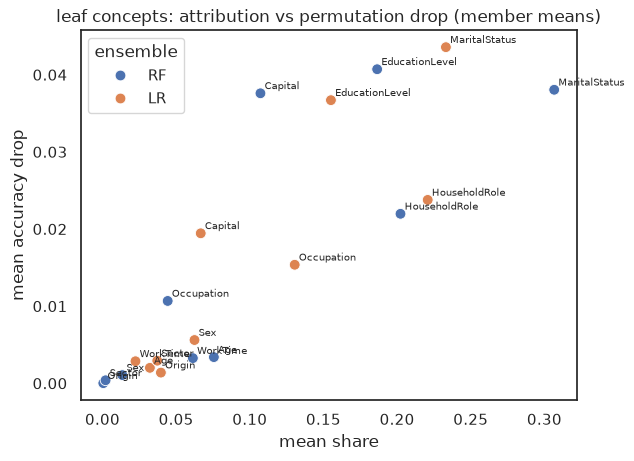

In [9]:
drop = {name: concepts.permutation_drop(m, X_te, y_te, labels["leaf"], names["leaf"]) for name, m in models.items()}
attr = {name: v[name, "leaf"].mean(axis=1) for name in models}
rho = pd.DataFrame({name: [spearmanr(a, d).statistic for a, d in zip(attr[name], drop[name])] for name in models})
print("per-member Spearman(attribution, accuracy drop):")
print(rho.describe().round(3))

faith = pd.concat([
    pd.DataFrame({"ensemble": name, "concept": names["leaf"], "mean share": attr[name].mean(0),
                  "mean accuracy drop": drop[name].mean(0)}) for name in models
])
ax = sns.scatterplot(faith, x="mean share", y="mean accuracy drop", hue="ensemble", s=60)
for _, r in faith.iterrows():
    ax.annotate(r.concept, (r["mean share"], r["mean accuracy drop"]), fontsize=7, xytext=(3, 3),
                textcoords="offset points")
ax.set_title("leaf concepts: attribution vs permutation drop (member means)")
plt.gcf().savefig(FIG / "faithfulness.png", dpi=200, bbox_inches="tight")
faith.pivot(index="concept", columns="ensemble", values=["mean share", "mean accuracy drop"]).round(3)

## Findings

Chance levels come from the `shuffled` reference (top agreement 0.25 / 0.15, entropy 0.99 / 0.98, Kendall 0).

- **RQ1 - members agree far above chance.** The most common top concept is shared by 83% (RF) / 79% (LR) of members at
  the top level and by 53% / 51% at the leaf level (chance: 25% / 15%). Mean pairwise Kendall tau-b is 0.41 / 0.48
  (top) and 0.35 / 0.37 (leaf). Agreement is partial, not unanimous: at the leaf level about half the members name a
  different top concept than the majority.
- **RQ1 - level matters.** Agreement is clearly higher at the top level (all three metrics). Most of the gain comes from
  `Family`: members split into a `MaritalStatus` group and a `HouseholdRole` group (heatmap), two features that carry
  the same signal (married / husband-wife). At the leaf level these groups disagree; at the top level both are `Family`,
  which is the top concept in 76-77% of (member, sample) pairs. The ontology turns a substitution between correlated
  features into agreement on one concept.
- **RQ3 - trees agree on the main concept, LR on the full ranking.** RF members agree more on the top concept (top
  agreement +0.05 / +0.03, lower entropy) but less on the full ranking (Kendall -0.07 / -0.02; LR higher on 83% of
  samples at the top level). A depth-5 path touches at most 5 features, so tree attribution is concentrated: `Origin`,
  `Sector`, `Sex` get almost nothing and the unused concepts tie. LR members spread weight over every concept they
  see (`Occupation` 0.13, `Sex` 0.06, `Origin` and `Sector` 0.04). RF members also specialise more (member spread on
  `HouseholdRole` / `MaritalStatus` 0.20 vs 0.12-0.16 for LR).
- **ProtectedAttribute.** On average 22% (RF) and 30% (LR) of a member's attribution goes to `race`, `sex` or
  `relationship`, up to 65-68% for single members; in 17% / 14% of (member, sample) pairs it is more than half. Most of
  it is `relationship` (`HouseholdRole`); LR members also use `sex` and `race` directly.
- **Faithfulness.** Attribution and permutation drop rank concepts alike: per-member Spearman median 0.78 (RF) and
  0.90 (LR), positive for every member (min 0.29 / 0.63). The main mismatch is `HouseholdRole`: high attribution, but a
  lower drop than `EducationLevel` or `MaritalStatus`, because `marital-status` still carries the signal when
  `relationship` is permuted. Attribution measures use, not irreplaceability.
- **Limitations.** Concept vectors use absolute contributions, so they show which concepts a member uses, not in which
  direction. Tree contributions are Saabas path credits (order-dependent), not Shapley values.